In [1]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("Iris.csv")

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [5]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [6]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [7]:
df = df.drop("Id", axis=1)

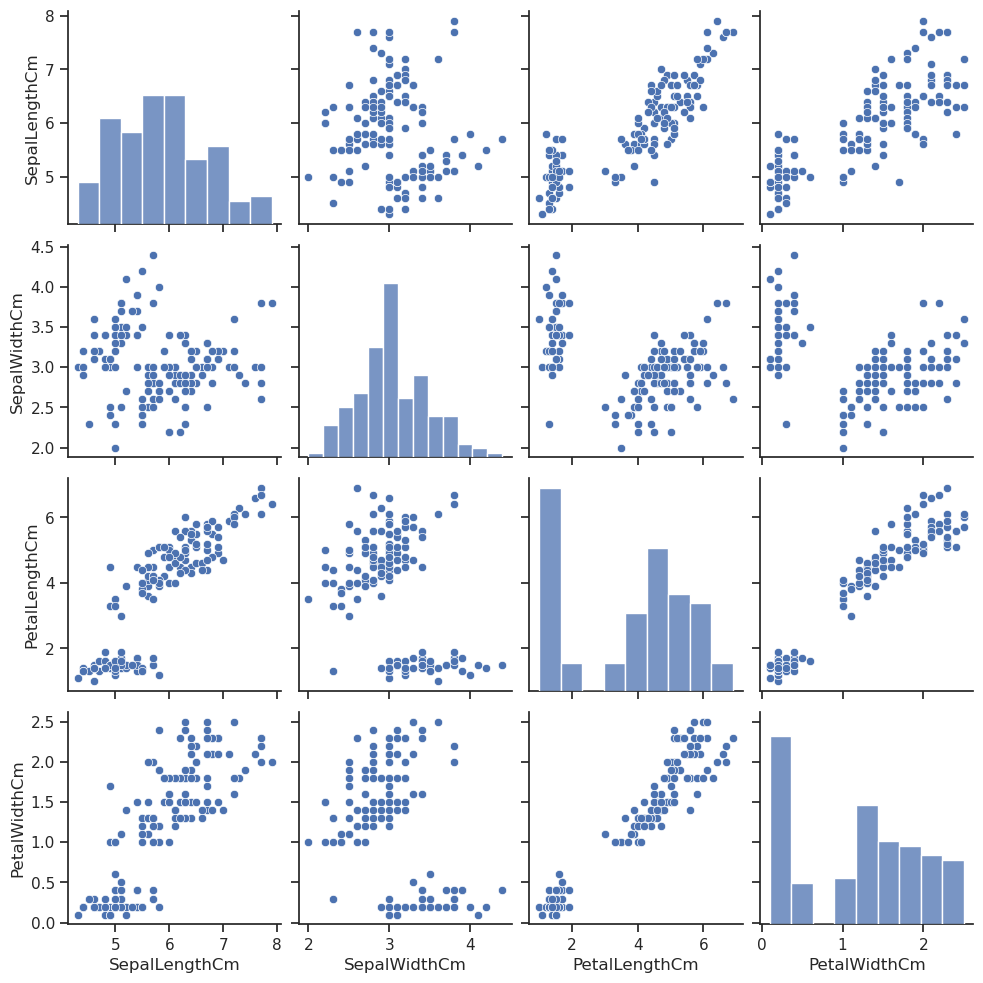

In [8]:
sns.set_theme(style=("ticks"))
sns.pairplot(
    data=df
    )
plt.show()

In [9]:
df.columns

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

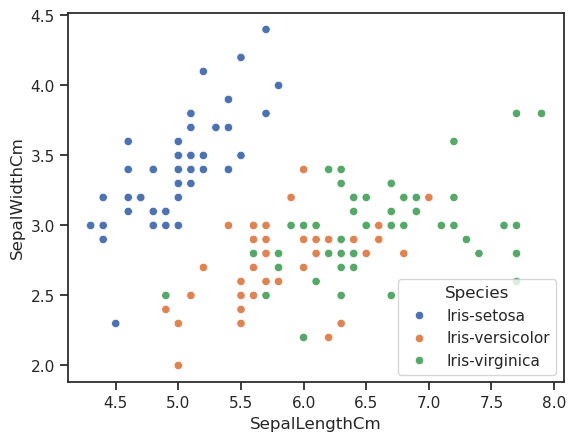

In [10]:
sns.set_theme(style=("ticks"))
sns.scatterplot(
    x = df["SepalLengthCm"],
    y = df["SepalWidthCm"],
    legend = True,
    hue = df["Species"]
)
plt.show()

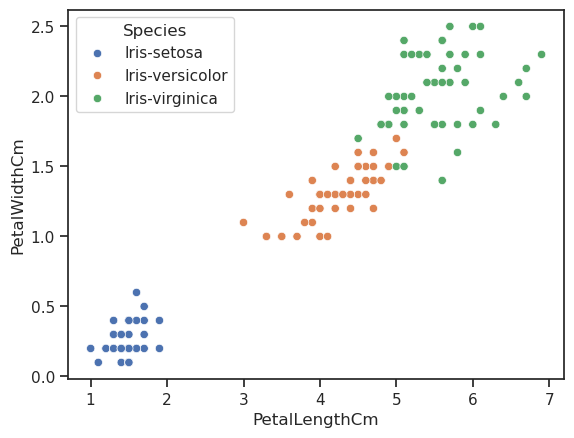

In [11]:
sns.set_theme(style=("ticks"))
sns.scatterplot(
    x = df["PetalLengthCm"],
    y = df["PetalWidthCm"],
    legend = True,
    hue = df["Species"]
)
plt.show()

In [12]:
from sklearn.preprocessing import StandardScaler, LabelEncoder # encoding yapilacaksa tran_test_split yaptintan sonra X_trainle yapip X_testi fit_transform yapip 
                                                               #sonra transform yapmak daha mantikli.

In [13]:
label = LabelEncoder()
df["Species"] = label.fit_transform(df["Species"])

In [14]:
df.tail()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


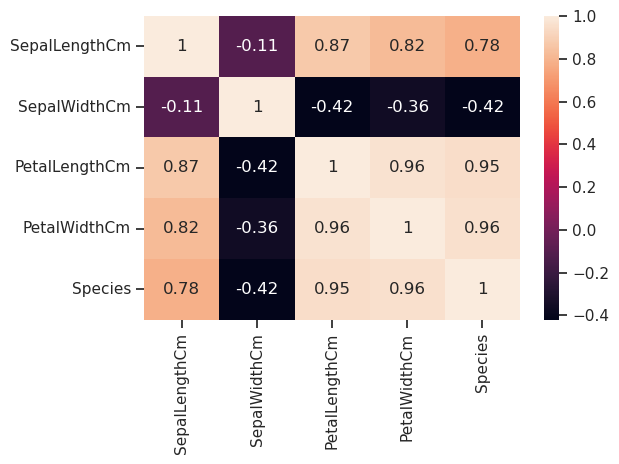

In [15]:
df_corr = df.corr()
sns.heatmap(data=df_corr, annot=True)
plt.tight_layout()
plt.show()

In [16]:
X = df.drop("Species", axis=1)
y = df["Species"]

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()

In [20]:
gnb.fit(X_train_scaled, y_train)
y_pred = gnb.predict(X_test_scaled)

print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification_report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Accuracy Score:  1.0
------------------------------------------------------------
Classification_report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38

------------------------------------------------------------
Confusion Matrix: 
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 12]]


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression())
])

pipeline.fit(X_train, y_train)
y_pred1 = pipeline.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred1))
print("-"*60)
print("Classification_report: \n", classification_report(y_test, y_pred1))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred1))

Accuracy Score:  1.0
------------------------------------------------------------
Classification_report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38

------------------------------------------------------------
Confusion Matrix: 
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 12]]


In [22]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [23]:
params_logistic = [
    {
    "logistic__penalty" : ["l1"],
    "logistic__C" : [0.1, 1, 10, 100],
    "logistic__solver" : ["liblinear", "saga"]
    },
    {
    "logistic__penalty": ["l2"],
    "logistic__C": [0.1, 1, 10],
    "logistic__solver": ["lbfgs", "newton-cg", "sag"],
    },
    {
    "logistic__penalty": ["elasticnet"],
    "logistic__C": [0.1, 1, 10],
    "logistic__solver": ["saga"],
    "logistic__l1_ratio": [0.2, 0.4, 0.6, 0.8]
    }
]             

In [24]:
cv = StratifiedKFold()

In [25]:
grid = GridSearchCV(
    pipeline,
    param_grid=params_logistic,
    cv=cv,
    scoring="accuracy"
)

grid.fit(X_train, y_train)
y_pred2 = grid.predict(X_test)

print("Best Parameters: ", grid.best_params_)
print("-"*60)
print("Best Score: ", grid.best_score_)
print("-"*60)
print("Accuracy Score: ", accuracy_score(y_test, y_pred2))
print("-"*60)
print("Classification_report: \n", classification_report(y_test, y_pred2))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred2))

Best Parameters:  {'logistic__C': 10, 'logistic__penalty': 'l2', 'logistic__solver': 'lbfgs'}
------------------------------------------------------------
Best Score:  0.9640316205533598
------------------------------------------------------------
Accuracy Score:  1.0
------------------------------------------------------------
Classification_report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38

------------------------------------------------------------
Confusion Matrix: 
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 12]]


In [26]:
from sklearn.svm import SVC

pipeline_1 = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

pipeline_1.fit(X_train, y_train)
y_pred3 = pipeline_1.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred3))
print("-"*60)
print("Classification_report: \n", classification_report(y_test, y_pred3))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred3))

Accuracy Score:  1.0
------------------------------------------------------------
Classification_report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38

------------------------------------------------------------
Confusion Matrix: 
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 12]]


In [27]:
params_svc = [
    {
    "svc__C" : [0.1, 1, 10, 100, 1000],
    "svc__kernel" : ["rbf"],
    "svc__gamma" : ["scale", "auto"],
    },
    {
    "svc__C" : [0.1, 1, 10, 100, 1000],
    "svc__kernel" : ["linear"]
    }
]    

In [28]:
grid = GridSearchCV(
    pipeline_1,
    param_grid=params_svc,
    cv=cv,
    scoring="accuracy"
)

grid.fit(X_train, y_train)
y_pred4 = grid.predict(X_test)

print("Best Parameters: ", grid.best_params_)
print("-"*60)
print("Best Score: ", grid.best_score_)
print("-"*60)
print("Accuracy Score: ", accuracy_score(y_test, y_pred4))
print("-"*60)
print("Classification_report: \n", classification_report(y_test, y_pred4))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred4))

Best Parameters:  {'svc__C': 1, 'svc__kernel': 'linear'}
------------------------------------------------------------
Best Score:  0.9640316205533598
------------------------------------------------------------
Accuracy Score:  1.0
------------------------------------------------------------
Classification_report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38

------------------------------------------------------------
Confusion Matrix: 
 [[12  0  0]
 [ 0 14  0]
 [ 0  0 12]]
